#### Université de Bordeaux,  Master Mention Informatique

# Analyse, classification et indexation des données : feuille 3
### Régression linéaire simple et multiple

##### Avant de commencer :

Le régression linéaire est l'une des méthodes statistiques les plus utilisées en sciences de données. Elle est utilisée pour <em>prédire</em> les valeurs d'une variable <em>dépendante</em> continue en fonction d'une ou plusieurs variables <em>indépendantes</em>.


In [2]:
import pandas as pd

### Exercice 1. Régression linéaire simple.

La gérante d’un commerce veut évaluer l’impact des frais déboursés en publicité par mois (représentés par une variable $X$ exprimée en milliers d’euros) sur le chiffre d’affaires mensuel (représenté par une variable $Y$ exprimée en milliers d’euros). On aimerait évaluer dans quelle mesure une modification du budget publicitaire mensuel affecterait le chiffre d’affaires mensuel. On a donc recueilli sur une période de 10 mois les données du tableau ci-dessous.

<table>
<tr><td>Chiffre d'affaires</td> <td>220</td> <td>280</td> <td>250</td> <td>170</td> <td>150</td> <td>340</td> <td>310</td> <td>210</td> <td>180</td> <td>190</td></tr>
<tr><td>Frais publicitaires</td> <td>2.6</td> <td>2.6</td> <td>2.4</td> <td>1.5</td> <td>0.9</td> <td>3.0</td> <td>2.7</td> <td>2.3</td> <td>1.7</td> <td>1.9</td></tr>

</table>    

1. Créer un <code>DataFrame</code> contenant les données du tableau ci-dessus.

In [4]:
data = {"CA": [220,280,250,170,150,340,310,210,180,190],
        "FP": [2.6,2.6,2.4,1.5,0.9,3.0,2.7,2.3,1.7,1.9]}
df = pd.DataFrame(data)
print(df)

    CA   FP
0  220  2.6
1  280  2.6
2  250  2.4
3  170  1.5
4  150  0.9
5  340  3.0
6  310  2.7
7  210  2.3
8  180  1.7
9  190  1.9


2. Tracer le nuage de points et estimer le coefficient de corrélation linéaire.

Text(0, 0.5, 'CA')

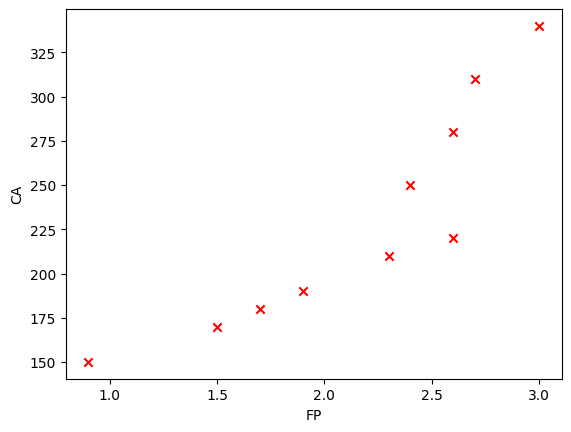

In [16]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.scatter(df['FP'],df['CA'], color='r', marker='x')
plt.xlabel('FP')
plt.ylabel('CA')

In [8]:
df.corr()

,CA,FP
CA,1.000000,0.893758
FP,0.893758,1.000000


3. Etablir la droite de régression correspondant à ce problème et tracer cette droite. Vous pouvez utiliser l'instruction <code>linregress</code> du module <code>stats</code>

In [39]:
X = df['FP']
Y = df['CA']

LinregressResult(slope=np.float64(87.40701381509031), intercept=np.float64(41.20085015940495), rvalue=np.float64(0.8937577901006998), pvalue=np.float64(0.0004894341749604697), stderr=np.float64(15.50930060045945), intercept_stderr=np.float64(34.825201199589735))


Text(0, 0.5, 'CA')

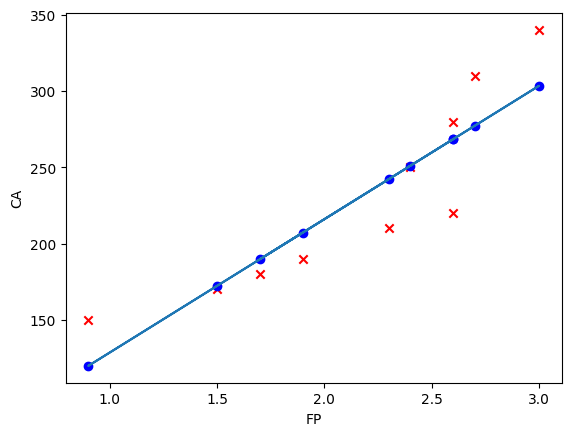

In [40]:
from scipy import stats
slope, intercept, rvalue, pvalue, _ = stats.linregress(X,Y)
print(stats.linregress(X,Y))
dR = slope * X + intercept
plt.scatter(X,Y, color='r', marker='x')
plt.scatter(X, dR, color='b')
plt.plot(X,dR)
plt.xlabel('FP')
plt.ylabel('CA')

4. Tester la significativité de la régression au risque 5%.

In [41]:
print('p_value = ', pvalue)

p_value =  0.0004894341749604697


5. Calculer le coefficient de détermination.

In [42]:
print('R² =', rvalue*rvalue)

R² = 0.7988029873656866


6. Quel serait le chiffre d’affaires mensuel prédit par le modèle pour un budget publicitaire mensuel de 400 euros ? de 4000 euros ?

In [47]:
def predict(x):
    return slope * x + intercept

print("Une estimation du CA prédit pour un bugdet publicitaire de 400 euros est :", predict(0.4))
print("Une estimation du CA prédit pour un bugdet publicitaire de 4000 euros est :", predict(4))

Une estimation du CA prédit pour un bugdet de 400 euros est : 76.16365568544109
Une estimation du CA prédit pour un bugdet de 4000 euros est : 390.8289054197662


### Exercice 2. Régression linéaire multiple

Nous voulons savoir quels sont les facteurs importants qui influencent la valeur d’une propriété. L'objectif est de construire un modèle qui nous aidera à évaluer cette valeur selon ces facteurs. Pour ce faire, nous utilisons la valeur totale pour un échantillon de 79 propriétés dans une région donnée. Voir le fichier <code>proprietes.csv</code> disponible à l’adresse :

http://www.labri.fr/~zemmari/datasets/proprietes.csv

Le fichier contient les variables suivantes correspondant chacune à un facteur : 
- Valeur Totale : valeur globale de la propriété
- Valeur Terrain : valeur du terrain sur lequel est bâtie la maison
- Acre : Superficie en acres
- Pieds2 : Superficie en pieds2
- Extérieur : Etat extérieur
- Chauffage : Type du chauffage utilisé
- Pièces : Nombre de pièces dans la maison
- Chambres : Nombre de chambres dans la maison
- SbainsC : Nombre de salles de bain complètes
- Sbains : Nombre de salles de bain non complètes
- Foyers : Nombre de foyers
- Garage : Indique si la propriété contient un garage ou non.

Après avoir chargé les données dans un DataFrame vous pouvez visualiser les premières entrées avec la fonction head et inspecter globalement les données avec la fonction info. Y a-t-il des données manquantes?

In [56]:
data = pd.read_csv('proprietes.csv', delimiter=';')
data.head()

,Valeur Totale,Valeur Terrain,Acre,Pied2,Extérieur,Chauffage,Pièces,Chambre,SbainsC,Sbains,Foyers,Garage
0,199657,63247,"1,63",1726,Good,NatGas,8,4,2,1,2,Garage
1,78482,38091,"0,495",1184,Good,NatGas,6,2,1,0,0,NoGarage
2,119962,37665,"0,375",1014,Good,Electric,7,3,2,0,1,Garage
3,116492,54062,"0,981",1260,Average,Electric,6,3,2,0,1,Garage
4,131263,61546,"1,14",1314,Average,NatGas,8,4,2,1,2,NoGarage


In [57]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Valeur Totale   79 non-null     int64 
 1   Valeur Terrain  79 non-null     int64 
 2   Acre            79 non-null     object
 3   Pied2           79 non-null     int64 
 4   Extérieur       79 non-null     object
 5   Chauffage       79 non-null     object
 6   Pièces          79 non-null     int64 
 7   Chambre         79 non-null     int64 
 8   SbainsC         79 non-null     int64 
 9   Sbains          79 non-null     int64 
 10  Foyers          79 non-null     int64 
 11  Garage          79 non-null     object
dtypes: int64(8), object(4)
memory usage: 7.5+ KB


1. Y a-t-il un lien entre la valeur totale et les différents facteurs ?

In [58]:
data = data.drop(columns=['Acre', 'Extérieur', 'Chauffage', 'Garage'])
data.corr()

,Valeur Totale,Valeur Terrain,Pied2,Pièces,Chambre,SbainsC,Sbains,Foyers
Valeur Totale,1.000000,0.814685,0.766510,0.626500,0.582365,0.626234,0.435950,0.547980
Valeur Terrain,0.814685,1.000000,0.515980,0.517940,0.497388,0.505859,0.235842,0.496970
Pied2,0.766510,0.515980,1.000000,0.562823,0.431150,0.457476,0.353999,0.364592
Pièces,0.626500,0.517940,0.562823,1.000000,0.790934,0.479091,0.488519,0.394377
Chambre,0.582365,0.497388,0.431150,0.790934,1.000000,0.585968,0.166039,0.399628
SbainsC,0.626234,0.505859,0.457476,0.479091,0.585968,1.000000,0.171758,0.485582
Sbains,0.435950,0.235842,0.353999,0.488519,0.166039,0.171758,1.000000,0.385958
Foyers,0.547980,0.496970,0.364592,0.394377,0.399628,0.485582,0.385958,1.000000


2. Afficher les valeurs des différentes statistiques desciptives.

In [60]:
data.describe()

,Valeur Totale,Valeur Terrain,Pied2,Pièces,Chambre,SbainsC,Sbains,Foyers
count,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000
mean,187253.405063,65899.481013,1677.911392,8.518987,3.987342,2.240506,0.721519,1.974684
std,84401.421337,22986.951385,634.638847,2.401179,1.265860,1.283177,0.714981,1.367898
min,74365.000000,35353.000000,672.000000,5.000000,2.000000,1.000000,0.000000,0.000000
25%,123089.000000,48002.000000,1147.000000,7.000000,3.000000,1.000000,0.000000,1.000000
50%,156761.000000,59861.000000,1628.000000,8.000000,4.000000,2.000000,1.000000,2.000000
75%,235277.500000,77868.000000,2022.000000,10.000000,5.000000,3.000000,1.000000,2.500000
max,453744.000000,131224.000000,3501.000000,18.000000,8.000000,7.000000,3.000000,7.000000


3. Faites les différentes régressions linéaires simples possibles, et choisissez la (ou les) plus pertinente(s).

In [61]:
Y = data['Valeur Totale']
columns = ['Valeur Terrain','Pied2','Pièces','Chambre','SbainsC','Sbains','Foyers']

In [67]:
for j in range(len(columns)):
    slope, intercept, rvalue, pvalue, _ = stats.linregress(data[columns[j]],Y)
    rvalueSquare = rvalue*rvalue
    print('Modèle ', j+1)
    print('------- Valeur Totale = ', intercept, ' + ', slope, ' * ', columns[j])
    print('------- R^2 = ', rvalueSquare)
    print('        Donc {:2.2f}% de la variabilité de la valeur totale est expliquée par {:s}'.format(
        rvalue *100,columns[j]))
    print('------- p_value = ', pvalue)   
    print('        H0: beta_1 = 0')
    if pvalue < 0.05 :
        print('        ', pvalue, '<= 5%', '==> on rejette H0, au risque alpha = 5%')
        print('         le modèle ', j+1, ' est bien pertinent.')
    else:
        print('        ', pvalue, '> 5%', '==> on ne rejette pas H0, au risque alpha = 5%')
        print('         on ne peut pas conclure sur le modèle ', j+1, ' car pas statistiquement significatif.')

Modèle  1
------- Valeur Totale =  -9870.846451247635  +  2.9912868581874625  *  Valeur Terrain
------- R^2 =  0.6637115265551455
        Donc 81.47% de la variabilité de la valeur totale est expliquée par Valeur Terrain
------- p_value =  6.636865062557978e-20
        H0: beta_1 = 0
         6.636865062557978e-20 <= 5% ==> on rejette H0, au risque alpha = 5%
         le modèle  1  est bien pertinent.
Modèle  2
------- Valeur Totale =  16208.538146922976  +  101.939153456249  *  Pied2
------- R^2 =  0.5875378229047032
        Donc 76.65% de la variabilité de la valeur totale est expliquée par Pied2
------- p_value =  1.8250569973875542e-16
        H0: beta_1 = 0
         1.8250569973875542e-16 <= 5% ==> on rejette H0, au risque alpha = 5%
         le modèle  2  est bien pertinent.
Modèle  3
------- Valeur Totale =  -347.1329936950351  +  22021.459890790356  *  Pièces
------- R^2 =  0.39250189604893293
        Donc 62.65% de la variabilité de la valeur totale est expliquée par Pièces
--

4. Faites la régression multiple de la Valeur totale en fonction des autres facteurs (quand c’est possible). Analysez les résultats obtenus.  Appuyez vous sur l'exemple vu en cours pour la méthode à suivre et l'utilisation de bibliothèques.